# 05 - Classificação com CNN

Classificação dos espectrogramas (`mod_spectograms`) em 4 classes: `ictal`, `normal`, `pos_ictal` e `pre_ictal`. Treino e validação seguem o `splits.csv`.

Os três modelos têm o mesmo extrator (3 `Conv2D` 3x3 com 32, 64 e 128 filtros, cada uma com `MaxPooling2D`) e o mesmo treino (Adam, 30 épocas, mesma semente). Só muda o final:
- **CNN**: `Flatten` + `Dense(128)` + `Dropout(0.5)` + `Dense(4)`. ← este notebook
- **FCNN**: igual à CNN, com `Conv 1x1` no lugar das `Dense` e `GlobalAveragePooling2D` no lugar do `Flatten`.
- **Encoder-Decoder**: a FCNN com um decoder (3 `Conv2DTranspose`) antes da cabeça.

As métricas de teste estão no `06_metrics.ipynb`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense, Dropout

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
tf.keras.utils.set_random_seed(0)
print(tf.config.list_physical_devices('GPU'))

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Carregamento dos dados

In [2]:
splits = pd.read_csv(PROJECT_ROOT / 'data' / 'annotations' / 'splits.csv')
classes = sorted(splits['classe'].unique())
print(classes)

def carregar(conjunto):
    df = splits[splits['conjunto'] == conjunto]
    X, y = [], []
    for _, row in df.iterrows():
        caminho = PROJECT_ROOT / row['caminho'].replace('spectrograms', 'mod_spectograms')
        img = Image.open(caminho).convert('RGB').resize((224, 224))
        X.append(np.array(img) / 255.0)
        y.append(classes.index(row['classe']))
    return np.array(X, dtype='float32'), np.array(y)

X_train, y_train = carregar('treino')
X_val, y_val = carregar('validacao')
print(X_train.shape, X_val.shape)

def plotar_historico(history, titulo):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, metrica, nome in zip(axes, ['loss', 'accuracy'], ['Perda', 'Acurácia']):
        ax.plot(history.history[metrica], label='Treinamento')
        ax.plot(history.history['val_' + metrica], label='Validação')
        ax.set_title(f'{titulo} — {nome}')
        ax.set_xlabel('Épocas')
        ax.set_ylabel(metrica)
        ax.legend()
    plt.tight_layout()
    plt.show()

['ICTAL', 'NORMAL', 'POS_ICTAL', 'PRE_ICTAL']


(100, 224, 224, 3) (20, 224, 224, 3)


## Arquitetura

In [3]:
model = Sequential([
    Input(shape=(224, 224, 3)),
    # Extrator de features (igual nos três modelos)
    Conv2D(32, (3, 3), activation='relu', padding='same'),    # 224x224x32
    MaxPooling2D((2, 2)),                                     # 112x112x32
    Conv2D(64, (3, 3), activation='relu', padding='same'),    # 112x112x64
    MaxPooling2D((2, 2)),                                     # 56x56x64
    Conv2D(128, (3, 3), activation='relu', padding='same'),   # 56x56x128
    MaxPooling2D((2, 2)),                                     # 28x28x128
    # Classificador: camadas densas
    Flatten(),                                                # 100.352
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(4, activation='softmax'),
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 100352)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    12,845,184 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,938,948 (49.36 MB)

 Trainable params: 12,938,948 (49.36 MB)

 Non-trainable params: 0 (0.00 B)

## Treinamento

In [4]:
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
history = model.fit(X_train, y_train, epochs=30, validation_data=(X_val, y_val), verbose=2)

Epoch 1/30


4/4 - 12s - 3s/step - accuracy: 0.1400 - loss: 1.5362 - val_accuracy: 0.3500 - val_loss: 1.3993


Epoch 2/30


4/4 - 0s - 42ms/step - accuracy: 0.3300 - loss: 1.3603 - val_accuracy: 0.2500 - val_loss: 1.3705


Epoch 3/30


4/4 - 0s - 41ms/step - accuracy: 0.4200 - loss: 1.3491 - val_accuracy: 0.3500 - val_loss: 1.3155


... (50 outputs left out)

Epoch 29/30


4/4 - 0s - 38ms/step - accuracy: 0.9900 - loss: 0.0733 - val_accuracy: 0.3500 - val_loss: 3.4245


Epoch 30/30


4/4 - 0s - 38ms/step - accuracy: 0.9700 - loss: 0.0762 - val_accuracy: 0.4000 - val_loss: 2.8883


In [5]:
print(f"Acurácia final de treinamento: {history.history['accuracy'][-1]:.4f}")
print(f"Acurácia final de validação:   {history.history['val_accuracy'][-1]:.4f}")
print(f"Loss final de treinamento:     {history.history['loss'][-1]:.4f}")
print(f"Loss final de validação:       {history.history['val_loss'][-1]:.4f}")

Acurácia final de treinamento: 0.9700
Acurácia final de validação:   0.4000
Loss final de treinamento:     0.0762
Loss final de validação:       2.8883


## Gráficos

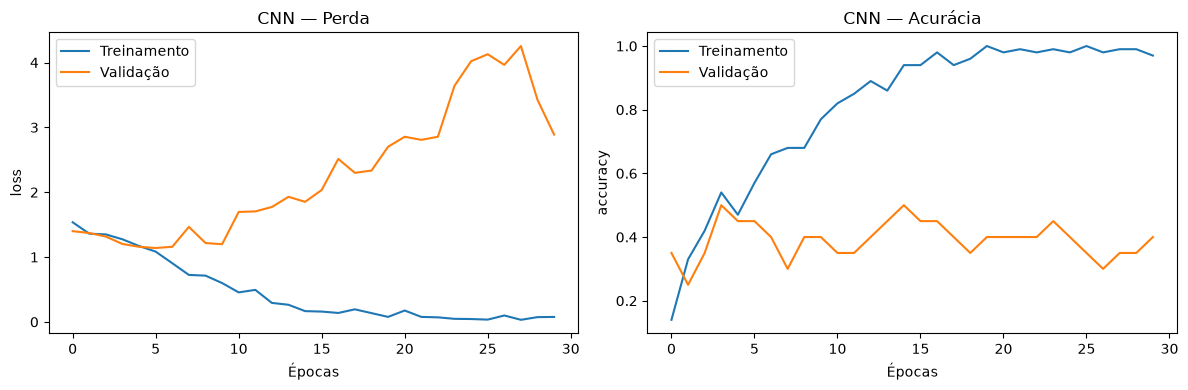

In [6]:
plotar_historico(history, 'CNN')

## Resultados (CNN)

**Overfitting.** A acurácia de treino chega a 97–100%, e a de validação fica entre 25% e 50% (termina em 40%). A `val_loss` é mínima na época 6 (1,14) e depois sobe até 4,25. Com 12,9 milhões de parâmetros e 100 imagens de treino, a rede decora o treino.

## Salvando o modelo

In [7]:
model.save(PROJECT_ROOT / 'models' / 'modelo_cnn.keras')

## Perguntas (CNN)

**O que faz o otimizador Adam?**
Ajusta uma taxa de aprendizado para cada peso, usando a média dos gradientes (momentum) e a média dos gradientes ao quadrado (RMSProp). Converge rápido sem precisar de muito ajuste.

**Por que a camada final usa Softmax?**
Ela transforma as 4 saídas em probabilidades que somam 1, e a classe prevista é a de maior probabilidade.

**Quantas camadas convolucionais existem?**
3 (32, 64 e 128 filtros).

**Quantas camadas de pooling existem?**
3 (`MaxPooling2D` 2x2).

**Quantos parâmetros possui a rede?**
12.938.948, sendo 99% na `Dense(128)`:

| Camada | Saída | Parâmetros |
|---|---|---|
| Conv2D (32) | 224x224x32 | 896 |
| MaxPooling2D | 112x112x32 | 0 |
| Conv2D (64) | 112x112x64 | 18.496 |
| MaxPooling2D | 56x56x64 | 0 |
| Conv2D (128) | 56x56x128 | 73.856 |
| MaxPooling2D | 28x28x128 | 0 |
| Flatten | 100.352 | 0 |
| Dense (128) | 128 | 12.845.184 |
| Dropout | 128 | 0 |
| Dense (4) | 4 | 516 |

**Qual camada é responsável pela classificação final?**
A `Dense(4, activation='softmax')`.

## Próximo passo

A avaliação no conjunto de teste está no notebook `06_metrics.ipynb`.